# Chapitre 7 - Cours 4 : fusion de modèles et tactiques de finetuning

Ce dernier notebook de cours couvre la fin du chapitre 7 : la sous-section *Model Merging
and Multi-Task Finetuning* (*Summing*, *Layer stacking*, *Concatenation*) et la section
*Finetuning Tactics* (*Finetuning frameworks and base models*, *Finetuning
hyperparameters*). La fusion est encore expérimentale ; on implémente donc les méthodes à
la main (`c7.linear_merge`, `c7.task_arithmetic`, `c7.slerp`, `c7.ties_merge`, `c7.dare`),
d'abord sur des vecteurs, puis sur de petits réseaux, pour en voir le fonctionnement. Les
tactiques sont illustrées par de vrais finetunings LoRA courts sur la tâche des tickets.

1. pourquoi fusionner (multi-tâche, oubli catastrophique, fusion contre ensemble) ;
2. fusion par somme : moyenne et arithmétique des tâches ;
3. SLERP ;
4. élaguer les paramètres redondants : TIES et DARE ;
5. empilement de couches et concaténation ;
6. choisir un modèle de base, une méthode et un framework ;
7. le taux d'apprentissage ;
8. taille de lot, accumulation de gradient et nombre d'époques ;
9. le poids de la perte du prompt.

In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
DOMS = ["bruité", "occulté", "décalé"]
DCOL = {"original": SLATE, "bruité": INDIGO, "occulté": AMBER, "décalé": TEAL}

## 1. Pourquoi fusionner des modèles (section *Model Merging and Multi-Task Finetuning*)

Le finetuning modifie **un** modèle ; la **fusion** (*model merging*) en combine
**plusieurs**, souvent des finetunings d'une même base, pour obtenir un modèle qui vaut
mieux que ses constituants pris séparément. Les bénéfices cités par le livre :

- **qualité** : deux modèles bons sur des parties différentes d'une tâche peuvent donner
  un modèle meilleur que chacun ;
- **mémoire et coût** : un seul modèle pour plusieurs tâches, idéal pour le déploiement
  **sur appareil** (téléphones, voitures, robots) où la mémoire manque ;
- **multi-tâche** sans les écueils des deux approches classiques : le finetuning
  **simultané** (toutes les tâches mélangées, qui demande plus de données) et le
  finetuning **séquentiel**, sujet à l'**oubli catastrophique** (Kirkpatrick et al.) ;
- **apprentissage fédéré** : fusionner des copies d'un modèle entraînées sur des appareils
  différents ;
- **sans GPU** : une fusion sans finetuning ultérieur se calcule sur CPU.

La fusion se distingue de l'**ensemble** : un ensemble combine les **sorties** de
plusieurs modèles intacts (vote, moyenne), au prix de plusieurs inférences par requête ;
la fusion combine les **paramètres**, et l'on n'a plus qu'un modèle à servir.

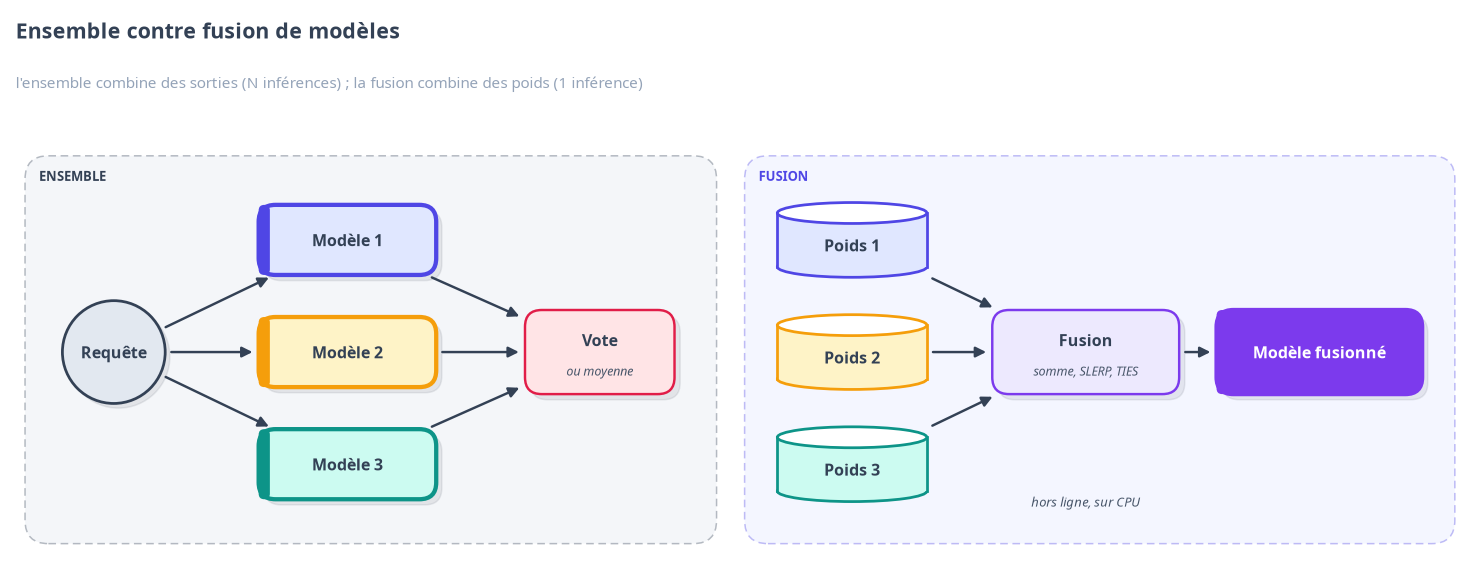

In [2]:
d = Diagram(15.6, 5.0, title="Ensemble contre fusion de modèles",
            subtitle="l'ensemble combine des sorties (N inférences) ; la fusion combine des poids (1 inférence)")
d.group(0.15, 0.25, 7.55, 4.4, "ensemble", SLATE)
d.box("q1", 1.1, 2.3, "Requête", color=SLATE, kind="user", w=1.1)
for i, (nm, col) in enumerate([("m1", INDIGO), ("m2", AMBER), ("m3", TEAL)]):
    d.box(nm, 3.6, 3.5 - i * 1.2, f"Modèle {i + 1}", color=col, kind="model", w=1.9, h=0.75)
    d.arrow("q1", nm)
d.box("vote", 6.3, 2.3, "Vote", sub="ou moyenne", color=ROSE, w=1.6)
for nm in ["m1", "m2", "m3"]:
    d.arrow(nm, "vote")
d.group(7.85, 0.25, 15.45, 4.4, "fusion", INDIGO)
for i, (nm, col) in enumerate([("w1", INDIGO), ("w2", AMBER), ("w3", TEAL)]):
    d.box(nm, 9.0, 3.5 - i * 1.2, f"Poids {i + 1}", color=col, kind="db", w=1.6, h=0.8)
d.box("mg", 11.5, 2.3, "Fusion", sub="somme, SLERP, TIES", color=VIOLET, w=2.0)
for nm in ["w1", "w2", "w3"]:
    d.arrow(nm, "mg")
d.box("mm", 14.0, 2.3, "Modèle fusionné", color=VIOLET, kind="model", w=2.2, filled=True)
d.arrow("mg", "mm")
d.note(11.5, 0.7, "hors ligne, sur CPU", fontsize=8.5)
d.show()

**Notre terrain d'expérience.** Pour expérimenter vite et sur CPU, on reproduit le
scénario « modèle de fondation + finetunings » à petite échelle avec le jeu `digits` de
scikit-learn (images 8 x 8 de chiffres manuscrits). `c7.digits_merge_setup` :

1. **pré-entraîne** un MLP (64 -> 256 -> 256 -> 10, 85 000 paramètres) sur les images
   originales et un peu d'images perturbées ;
2. le **finetune** séparément sur trois « tâches » : images **bruitées**, **occultées**
   (un carré 4 x 4 masqué) et **décalées** d'un pixel.

Commençons par l'oubli catastrophique : finetunons la base **séquentiellement** sur les
trois tâches et suivons l'exactitude sur chacune.

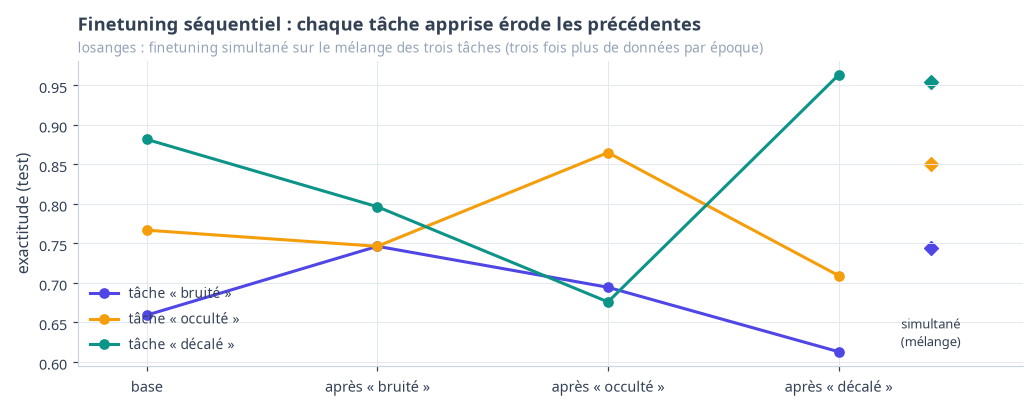

In [3]:
S = c7.digits_merge_setup()
T = S.tasks
seq_hist = [("base", S.evaluate(S.base))]
net = c7.make_mlp(0, S.hidden); c7.set_flat(net, S.base)
for k in DOMS:
    c7.fit_mlp(net, T[k][0], T[k][1], epochs=10, lr=5e-4)
    seq_hist.append((f"après « {k} »", S.evaluate(c7.get_flat(net))))
Xmix = np.concatenate([T[k][0] for k in DOMS]); ymix = np.concatenate([T[k][1] for k in DOMS])
net_mix = c7.make_mlp(0, S.hidden); c7.set_flat(net_mix, S.base); c7.fit_mlp(net_mix, Xmix, ymix, epochs=10, lr=5e-4)
acc_mix = S.evaluate(c7.get_flat(net_mix))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
stages = [s for s, _ in seq_hist]
for k in DOMS:
    ax.plot(stages, [h[k] for _, h in seq_hist], "o-", color=DCOL[k], label=f"tâche « {k} »")
    ax.scatter([len(stages) - 0.6], [acc_mix[k]], marker="D", color=DCOL[k], s=40)
ax.text(len(stages) - 0.6, 0.62, "simultané\n(mélange)", ha="center", fontsize=8.5, color=SLATE)
ax.set_xlim(-0.3, len(stages) - 0.2); ax.set_ylabel("exactitude (test)"); ax.legend(fontsize=9, loc="lower left")
c7.title_sub(ax, "Finetuning séquentiel : chaque tâche apprise érode les précédentes",
             "losanges : finetuning simultané sur le mélange des trois tâches (trois fois plus de données par époque)")
plt.tight_layout(); plt.show()

Chaque finetuning fait progresser sa tâche puis, à l'étape suivante, une partie de ce
gain s'évapore : c'est l'oubli catastrophique, net même entre des tâches aussi proches. Le finetuning simultané évite l'oubli mais demande toutes les données en même
temps. La fusion propose une troisième voie : finetuner en **parallèle**, puis combiner.

> **À retenir.** La fusion combine des **paramètres** (un modèle à servir), l'ensemble
> des **sorties** (N inférences). Elle permet le multi-tâche sans oubli séquentiel ni
> réentraînement commun.

## 2. Fusion par somme : moyenne et arithmétique des tâches (section *Summing*)

**Combinaison linéaire.** Pour deux modèles $A$ et $B$ de même architecture :
$$\text{Merge}(A, B) = \frac{w_A A + w_B B}{w_A + w_B}.$$
D'une simplicité désarmante, elle marche étonnamment bien (Perrone, 1993 ; les *model
soups* de Wortsman et al., 2022, qui moyennent plusieurs finetunings et gagnent en
exactitude sans coût d'inférence). Elle est la plus efficace pour des modèles finetunés
**depuis la même base**. On raisonne alors en **vecteurs de tâche** (*task vectors*, ou
paramètres delta) :
$$\tau_t = \theta_t - \theta_{\text{base}}, \qquad \theta_{\text{fusion}} = \theta_{\text{base}} + \sum_t \lambda_t\, \tau_t.$$
C'est l'**arithmétique des tâches** (Ilharco et al., 2022) : additionner des vecteurs pour
cumuler des capacités, ou en **soustraire** un pour retirer un comportement (biais,
capacité indésirable). La moyenne simple de $n$ finetunings correspond à $\lambda_t = 1/n$.
Visualisons cette géométrie en deux dimensions.

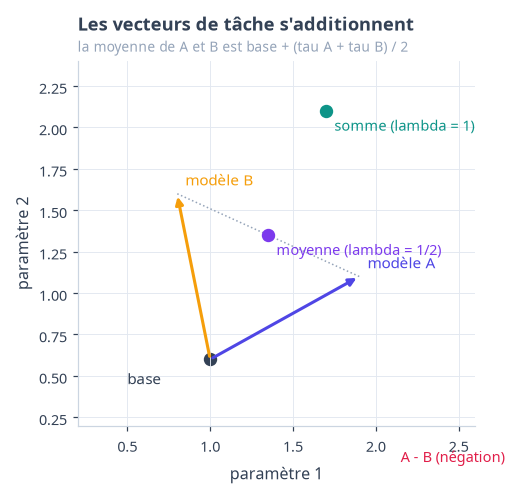

In [4]:
base2 = np.array([1.0, 0.6]); tA = np.array([0.9, 0.5]); tB = np.array([-0.2, 1.0])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for v, col, lab in [(tA, INDIGO, "tau A"), (tB, AMBER, "tau B")]:
    ax.annotate("", base2 + v, base2, arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
    ax.text(*(base2 + v + 0.05), f"modèle {lab[-1]}", color=col, fontsize=10)
pts = {"moyenne (lambda = 1/2)": base2 + 0.5 * (tA + tB), "somme (lambda = 1)": base2 + tA + tB,
       "A - B (négation)": base2 + tA - tB}
for (lab, p), col in zip(pts.items(), [VIOLET, TEAL, ROSE]):
    ax.scatter(*p, color=col, s=60, zorder=3); ax.text(p[0] + 0.05, p[1] - 0.12, lab, color=col, fontsize=9.5)
ax.scatter(*base2, color=SLATE, s=60); ax.text(base2[0] - 0.5, base2[1] - 0.15, "base", color=SLATE)
ax.plot(*np.array([base2 + tA, base2 + tB]).T, color=GRAY, ls=":", lw=1)
ax.set_xlim(0.2, 2.6); ax.set_ylim(0.2, 2.4); ax.set_aspect("equal")
ax.set_xlabel("paramètre 1"); ax.set_ylabel("paramètre 2")
c7.title_sub(ax, "Les vecteurs de tâche s'additionnent", "la moyenne de A et B est base + (tau A + tau B) / 2")
plt.tight_layout(); plt.show()

**Sur nos réseaux.** On fusionne les trois finetunings par arithmétique des tâches, avec
un coefficient commun $\lambda$ ($\lambda = 1/3$ : moyenne simple), et l'on mesure
l'exactitude sur chaque tâche. Repères : la base, et chaque spécialiste sur sa propre tâche.

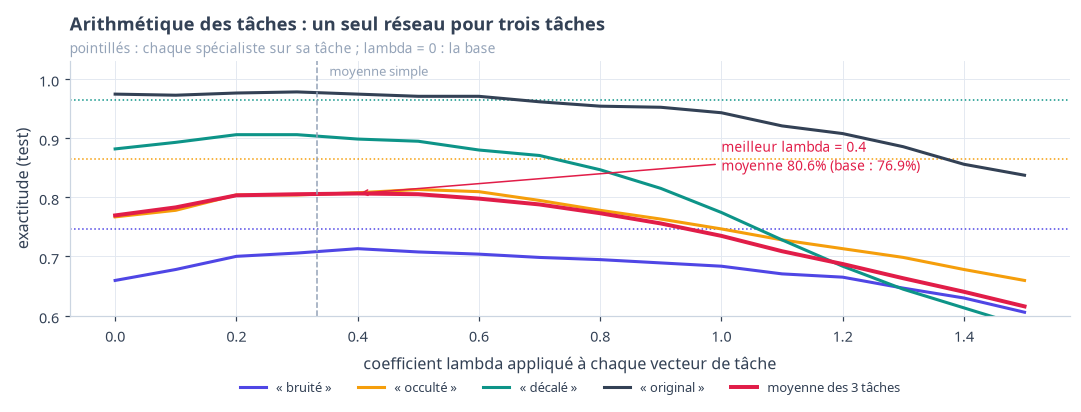

In [5]:
tv = S.task_vectors
lams = np.linspace(0, 1.5, 16)
ta = [S.evaluate(c7.task_arithmetic(S.base, list(tv.values()), l)) for l in lams]
acc_base = S.evaluate(S.base)
acc_spec = {k: S.evaluate(S.finetuned[k])[k] for k in DOMS}
fig, ax = plt.subplots(figsize=(10, 4))
for k in DOMS + ["original"]:
    ax.plot(lams, [a[k] for a in ta], color=DCOL[k], label=f"« {k} »")
    if k in DOMS:
        ax.axhline(acc_spec[k], color=DCOL[k], ls=":", lw=1)
avg = [np.mean([a[k] for k in DOMS]) for a in ta]
best = int(np.argmax(avg))
ax.plot(lams, avg, color=ROSE, lw=2.6, label="moyenne des 3 tâches")
ax.axvline(1 / 3, color=GRAY, ls="--", lw=1); ax.text(1 / 3 + 0.02, 1.005, "moyenne simple", color=GRAY, fontsize=8.5)
ax.annotate(f"meilleur lambda = {lams[best]:.1f}\nmoyenne {avg[best]:.1%} (base : {np.mean([acc_base[k] for k in DOMS]):.1%})",
            (lams[best], avg[best]), xytext=(1.0, 0.845), arrowprops=dict(arrowstyle="->", color=ROSE),
            fontsize=9, color=ROSE)
ax.set_xlabel("coefficient lambda appliqué à chaque vecteur de tâche"); ax.set_ylabel("exactitude (test)")
ax.set_ylim(0.6, 1.03); ax.legend(ncol=5, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
c7.title_sub(ax, "Arithmétique des tâches : un seul réseau pour trois tâches",
             "pointillés : chaque spécialiste sur sa tâche ; lambda = 0 : la base")
plt.tight_layout(); plt.show()

Autour de $\lambda \approx 0{,}3$ à $0{,}5$, le réseau fusionné fait mieux que la base sur
les **trois** tâches à la fois, sans perdre sur les images originales, mais reste en deçà
de chaque spécialiste sur sa propre tâche : c'est le prix de l'**interférence** entre
vecteurs de tâche. Trop grand, $\lambda$ éloigne le modèle de la zone où les finetunings
ont été appris et tout se dégrade.

**Négation de tâche.** Soustraire un vecteur doit retirer la capacité correspondante.
Retirons $\tau_{\text{décalé}}$ :

In [6]:
neg = pd.DataFrame({f"lambda = {l}": S.evaluate(c7.task_arithmetic(S.base, [tv["décalé"]], l))
                    for l in [1.0, 0.0, -1.0, -2.0]}).T
neg.round(3)

,original,bruité,occulté,décalé
lambda = 1.0,0.952,0.609,0.691,0.965
lambda = 0.0,0.974,0.659,0.767,0.881
lambda = -1.0,0.919,0.569,0.654,0.667
lambda = -2.0,0.772,0.419,0.467,0.393


Avec $\lambda < 0$, l'exactitude sur les images décalées chute nettement, alors que les
autres tâches baissent nettement moins : on a « désappris » une capacité de façon ciblée,
sans aucun réentraînement. C'est l'usage proposé pour retirer des comportements
indésirables acquis au pré-entraînement.

> **À retenir.** Fusionner des finetunings d'une même base revient à combiner leurs
> vecteurs de tâche : $\theta = \theta_{base} + \sum \lambda_t \tau_t$. L'addition cumule des
> capacités (avec interférence), la soustraction en retire.

## 3. SLERP (section *Spherical linear interpolation*)

Le livre présente l'**interpolation linéaire sphérique** sans formule ; la voici. Pour deux
vecteurs d'angle $\Omega$ entre leurs directions, et un facteur $t \in [0, 1]$ :
$$\text{slerp}(v_0, v_1; t) = \frac{\sin\big((1-t)\Omega\big)}{\sin \Omega}\, v_0 + \frac{\sin(t\Omega)}{\sin \Omega}\, v_1,
  \qquad \cos \Omega = \frac{v_0 \cdot v_1}{\|v_0\|\,\|v_1\|}.$$
Pour des vecteurs unitaires, le résultat reste sur la sphère : on suit le **grand cercle**
(le plus court chemin à la surface, comme une route aérienne entre deux villes). La
moyenne linéaire, elle, coupe à travers la sphère et **raccourcit** le vecteur : pour deux
vecteurs unitaires orthogonaux, le milieu linéaire a une norme $1/\sqrt 2 \approx 0{,}71$.
Notre `c7.slerp` interpole la direction sur le grand cercle et la norme linéairement.
Comme l'opération ne prend que deux vecteurs, on fusionne plus de deux modèles en
cascade.

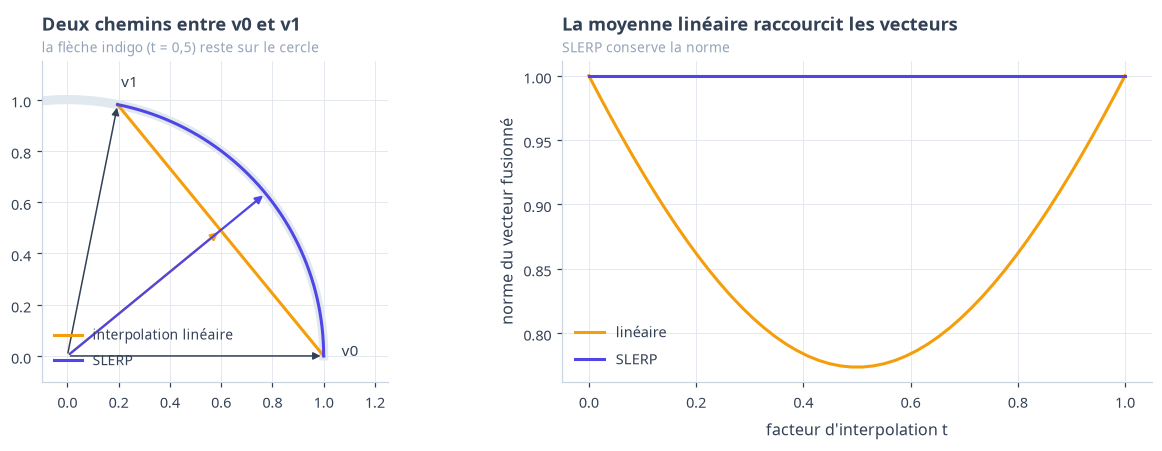

In [7]:
v0, v1 = np.array([1.0, 0.0]), np.array([0.2, 1.0]) / np.linalg.norm([0.2, 1.0])
ts = np.linspace(0, 1, 50)
lin = np.array([(1 - t) * v0 + t * v1 for t in ts]); sl = np.array([c7.slerp(v0, v1, t) for t in ts])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
th = np.linspace(0, np.pi / 2 + 0.3, 200)
axes[0].plot(np.cos(th), np.sin(th), color=LIGHT[SLATE], lw=6)
axes[0].plot(*lin.T, color=AMBER, label="interpolation linéaire")
axes[0].plot(*sl.T, color=INDIGO, label="SLERP")
for v, lab in [(v0, "v0"), (v1, "v1")]:
    axes[0].annotate("", v, (0, 0), arrowprops=dict(arrowstyle="-|>", color=SLATE)); axes[0].text(*(v * 1.07), lab)
m_l, m_s = 0.5 * (v0 + v1), c7.slerp(v0, v1, 0.5)
for m_, col in [(m_l, AMBER), (m_s, INDIGO)]:
    axes[0].annotate("", m_, (0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.5))
axes[0].set_aspect("equal"); axes[0].set_xlim(-0.1, 1.25); axes[0].set_ylim(-0.1, 1.15); axes[0].legend(fontsize=9, loc="lower left")
c7.title_sub(axes[0], "Deux chemins entre v0 et v1", "la flèche indigo (t = 0,5) reste sur le cercle")
axes[1].plot(ts, np.linalg.norm(lin, axis=1), color=AMBER, label="linéaire")
axes[1].plot(ts, np.linalg.norm(sl, axis=1), color=INDIGO, label="SLERP")
axes[1].set_xlabel("facteur d'interpolation t"); axes[1].set_ylabel("norme du vecteur fusionné"); axes[1].legend()
c7.title_sub(axes[1], "La moyenne linéaire raccourcit les vecteurs", "SLERP conserve la norme")
plt.tight_layout(); plt.show()

**Sur nos réseaux.** On interpole entre les spécialistes « bruité » et « occulté » (dans
l'espace des vecteurs de tâche), linéairement et par SLERP.

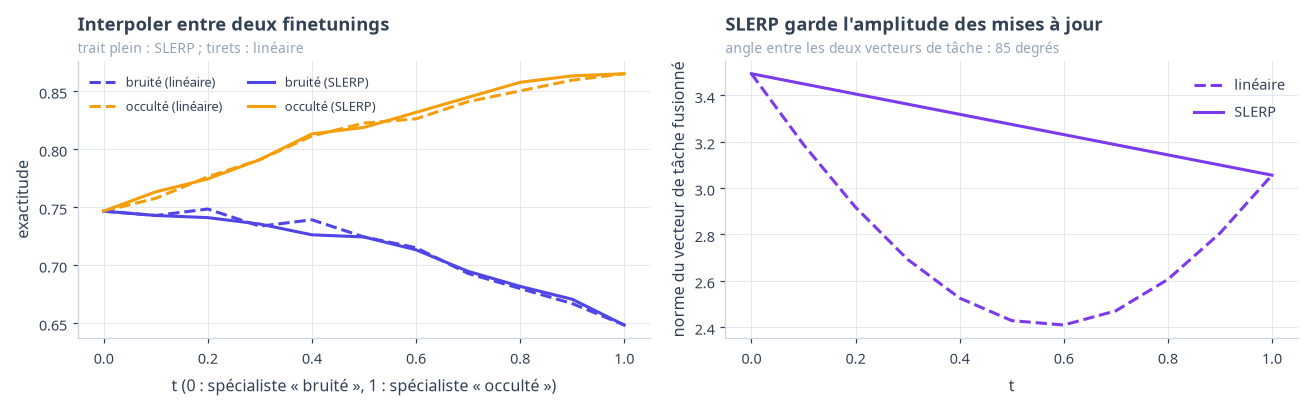

In [8]:
tts = np.linspace(0, 1, 11)
rows = []
for t in tts:
    for meth, f in [("linéaire", lambda a, b, t: (1 - t) * a + t * b), ("SLERP", c7.slerp)]:
        tau = f(tv["bruité"], tv["occulté"], t)
        acc = S.evaluate(S.base + tau)
        rows.append({"t": t, "méthode": meth, **acc, "norme de tau": np.linalg.norm(tau)})
sl_df = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for meth, ls in [("linéaire", "--"), ("SLERP", "-")]:
    sub = sl_df[sl_df["méthode"] == meth]
    for k in ["bruité", "occulté"]:
        axes[0].plot(sub["t"], sub[k], ls, color=DCOL[k], label=f"{k} ({meth})")
    axes[1].plot(sub["t"], sub["norme de tau"], ls, color=VIOLET, label=meth)
axes[0].set_xlabel("t (0 : spécialiste « bruité », 1 : spécialiste « occulté »)"); axes[0].set_ylabel("exactitude")
axes[0].legend(fontsize=8.5, ncol=2)
c7.title_sub(axes[0], "Interpoler entre deux finetunings", "trait plein : SLERP ; tirets : linéaire")
axes[1].set_xlabel("t"); axes[1].set_ylabel("norme du vecteur de tâche fusionné"); axes[1].legend()
c7.title_sub(axes[1], "SLERP garde l'amplitude des mises à jour", f"angle entre les deux vecteurs de tâche : "
             f"{np.degrees(np.arccos(tv['bruité'] @ tv['occulté'] / np.linalg.norm(tv['bruité']) / np.linalg.norm(tv['occulté']))):.0f} degrés")
plt.tight_layout(); plt.show()

Les vecteurs de tâche sont presque orthogonaux (c'est typique : en grande dimension, deux
finetunings indépendants vont dans des directions quasi perpendiculaires). La moyenne
linéaire réduit alors la norme de la mise à jour d'environ 30 % au milieu, ce qui
l'affaiblit ; SLERP la conserve. Sur ce petit exemple, les deux méthodes donnent des
exactitudes voisines : l'intérêt de SLERP se discute au cas par cas, ce qui explique que
les outils de fusion proposent les deux.

> **À retenir.** SLERP interpole sur le grand cercle et conserve la norme ; il ne fusionne
> que deux vecteurs à la fois. En grande dimension, les vecteurs de tâche sont presque
> orthogonaux, et la moyenne linéaire les raccourcit.

## 4. Élaguer les paramètres redondants : TIES et DARE (section *Pruning redundant task-specific parameters*)

Un finetuning modifie presque tous les paramètres, mais la plupart des modifications sont
minimes et inutiles à la tâche. Yadav et al. (2023) montrent (figure 7-17 du livre) qu'on
peut **remettre à zéro** la majorité des composantes d'un vecteur de tâche en ne gardant
que les plus grandes en valeur absolue, sans perte notable. Vérifions sur nos réseaux.

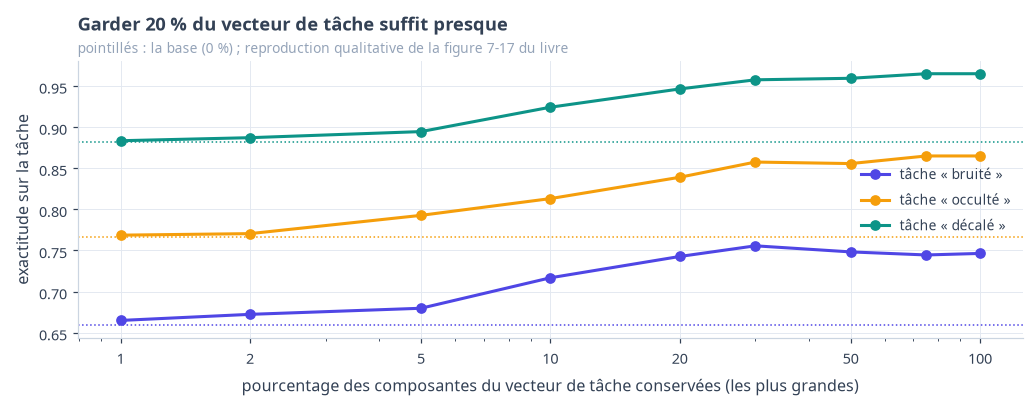

In [9]:
dens = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for k in DOMS:
    accs = [S.evaluate(S.base + c7.trim(tv[k], d_))[k] for d_ in dens]
    ax.plot(np.array(dens) * 100, accs, "o-", color=DCOL[k], label=f"tâche « {k} »")
    ax.axhline(acc_base[k], color=DCOL[k], ls=":", lw=1)
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50, 100], ["1", "2", "5", "10", "20", "50", "100"])
ax.set_xlabel("pourcentage des composantes du vecteur de tâche conservées (les plus grandes)")
ax.set_ylabel("exactitude sur la tâche"); ax.legend(fontsize=9)
c7.title_sub(ax, "Garder 20 % du vecteur de tâche suffit presque",
             "pointillés : la base (0 %) ; reproduction qualitative de la figure 7-17 du livre")
plt.tight_layout(); plt.show()

Ces composantes redondantes ne gênent pas un modèle seul, mais **interfèrent** quand on
fusionne : un petit changement inutile dans une tâche peut annuler un changement utile
d'une autre, surtout si leurs signes s'opposent. **TIES** (*TrIm, Elect Sign, and merge*,
acronyme qui fait souffrir l'auteure) procède en trois temps :

1. **élaguer** chaque vecteur de tâche (top-$k$ en magnitude) ;
2. **élire** pour chaque paramètre le signe dominant (signe de la somme des valeurs élaguées) ;
3. **fusionner** en moyennant seulement les valeurs qui ont le signe élu.

**DARE** (*Drop And REscale*) supprime **au hasard** une fraction $p$ des composantes et
multiplie les survivantes par $1/(1-p)$ : l'espérance du vecteur est conservée. Voici les
étapes de TIES sur trois petits vecteurs de 10 paramètres.

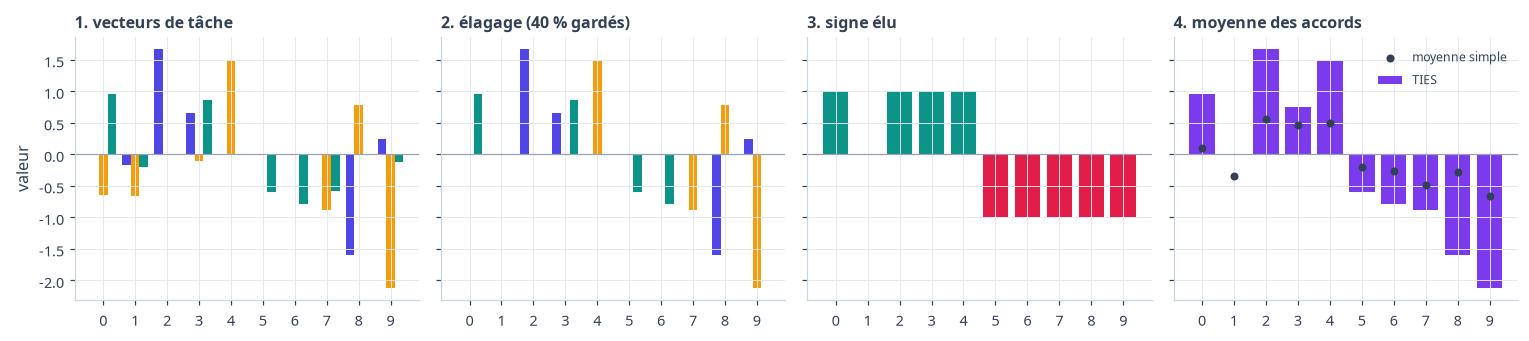

In [10]:
rng = np.random.default_rng(4)
small = [rng.normal(0, 1, 10) * (rng.random(10) < 0.8) for _ in range(3)]
trimmed = [c7.trim(v, 0.4) for v in small]
elected = np.sign(np.sum(trimmed, 0))
merged_t = c7.ties_merge(small, density=0.4)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
xk = np.arange(10)
for j, (v, col) in enumerate(zip(small, [INDIGO, AMBER, TEAL])):
    axes[0].bar(xk + (j - 1) * 0.27, v, 0.27, color=col)
    axes[1].bar(xk + (j - 1) * 0.27, trimmed[j], 0.27, color=col)
axes[2].bar(xk, elected, color=[TEAL if e > 0 else ROSE for e in elected])
axes[3].bar(xk, merged_t, color=VIOLET, label="TIES")
axes[3].scatter(xk, np.mean(small, 0), color=SLATE, zorder=3, s=18, label="moyenne simple")
axes[3].legend(fontsize=8)
for ax, t_ in zip(axes, ["1. vecteurs de tâche", "2. élagage (40 % gardés)", "3. signe élu", "4. moyenne des accords"]):
    ax.set_title(t_, fontsize=10.5); ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks(xk)
axes[0].set_ylabel("valeur")
plt.tight_layout(); plt.show()

Là où les trois vecteurs se contredisent, la moyenne simple s'annule presque ; TIES garde
la valeur portée par le camp majoritaire. Comparons les méthodes sur nos trois tâches, en
retenant pour chacune le meilleur coefficient global $\lambda$ (choisi sur une grille,
comme on le ferait sur un jeu de validation).

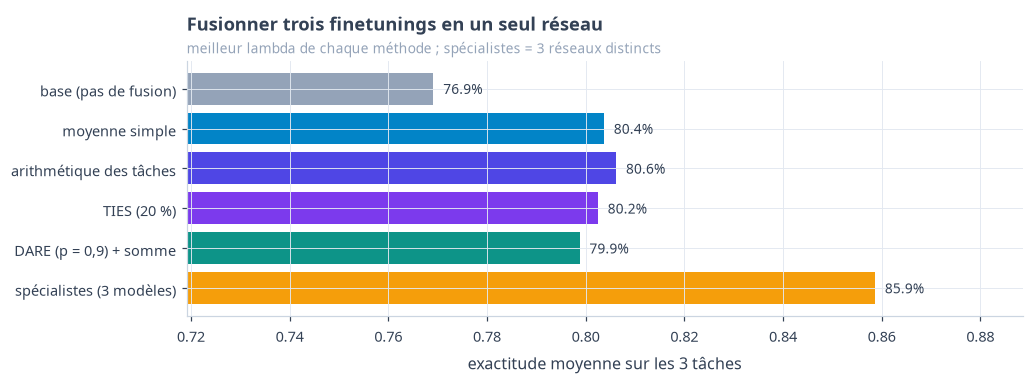

,original,bruité,occulté,décalé,moyenne 3 tâches,lambda
moyenne simple,0.976,0.706,0.802,0.904,0.804,NaN
arithmétique des tâches,0.974,0.713,0.807,0.898,0.806,0.4
TIES (20 %),0.972,0.709,0.809,0.889,0.802,0.6
"DARE (p = 0,9) + somme",0.969,0.704,0.802,0.891,0.799,0.2
base (pas de fusion),0.974,0.659,0.767,0.881,0.769,0.0
spécialistes (3 modèles),NaN,0.746,0.865,0.965,0.859,NaN


In [11]:
vecs = list(tv.values())
grid_l = np.linspace(0.1, 2.0, 20)


def best_of(make):
    best_ = None
    for l in grid_l:
        acc = S.evaluate(S.base + make(l))
        m = np.mean([acc[k] for k in DOMS])
        if best_ is None or m > best_[0]:
            best_ = (m, l, acc)
    return best_


methods = {
    "moyenne simple": lambda l: sum(vecs) / 3,
    "arithmétique des tâches": lambda l: l * sum(vecs),
    "TIES (20 %)": lambda l: c7.ties_merge(vecs, 0.2, l),
    "DARE (p = 0,9) + somme": lambda l: l * sum(c7.dare(v, 0.9, seed=i) for i, v in enumerate(vecs)),
}
res = {name: best_of(f) for name, f in methods.items()}
cmp_df = pd.DataFrame({name: {**{k: r[2][k] for k in ["original"] + DOMS}, "moyenne 3 tâches": r[0], "lambda": r[1]}
                       for name, r in res.items()}).T
cmp_df.loc["moyenne simple", "lambda"] = np.nan  # pas de coefficient à régler
cmp_df.loc["base (pas de fusion)"] = {**acc_base, "moyenne 3 tâches": np.mean([acc_base[k] for k in DOMS]), "lambda": 0}
cmp_df.loc["spécialistes (3 modèles)"] = {"original": np.nan, **acc_spec, "moyenne 3 tâches": np.mean(list(acc_spec.values())), "lambda": np.nan}
fig, ax = plt.subplots(figsize=(9.5, 3.6))
order = ["base (pas de fusion)", "moyenne simple", "arithmétique des tâches", "TIES (20 %)", "DARE (p = 0,9) + somme", "spécialistes (3 modèles)"]
vals = cmp_df.loc[order, "moyenne 3 tâches"]
ax.barh(order, vals, color=[GRAY, SKY, INDIGO, VIOLET, TEAL, AMBER])
for i, v in enumerate(vals):
    ax.text(v + 0.002, i, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlim(vals.min() - 0.05, vals.max() + 0.03); ax.invert_yaxis(); ax.set_xlabel("exactitude moyenne sur les 3 tâches")
c7.title_sub(ax, "Fusionner trois finetunings en un seul réseau", "meilleur lambda de chaque méthode ; spécialistes = 3 réseaux distincts")
plt.tight_layout(); plt.show()
cmp_df.round(3)

Sur ce petit réseau, toutes les fusions récupèrent une bonne partie de l'écart entre la
base et les spécialistes, et TIES ou DARE font **à peu près jeu égal** avec l'arithmétique
des tâches bien réglée. Les gains rapportés par leurs auteurs concernent de grands modèles
et de nombreuses tâches, où les occasions d'interférence se multiplient (plus il y a de
modèles à fusionner, plus l'élagage importe, note le livre). DARE montre en tout cas qu'on
peut jeter 90 % de chaque vecteur de tâche **au hasard** sans rien perdre, preuve de leur
redondance. Notez que l'élagage rend les **vecteurs de tâche** creux, pas le modèle
fusionné : le but est la qualité, pas la mémoire.

> **À retenir.** Les vecteurs de tâche sont très redondants (20 % des composantes, voire
> 10 % au hasard, suffisent). TIES et DARE élaguent avant de fusionner pour limiter les
> interférences ; leur intérêt croît avec le nombre de modèles fusionnés.

## 5. Empilement de couches et concaténation (sections *Layer stacking* et *Concatenation*)

**Empilement de couches** (*passthrough*, *frankenmerging*) : on prend des couches de
plusieurs modèles et on les empile, ce qui crée des architectures nouvelles, qui demandent
en général un finetuning ensuite. Exemples cités : Goliath-120B (deux Llama 2-70B), la
création de **mixtures d'experts** à partir d'un modèle dense (*sparse upcycling*,
Komatsuzaki et al., 2022 : on duplique des couches feed-forward et on ajoute un routeur),
et l'**agrandissement en profondeur** de SOLAR 10.7B (Kim et al., 2023) : deux copies d'un
modèle de 32 couches, 16 couches sommées, d'où $32 \times 2 - 16 = 48$ couches.

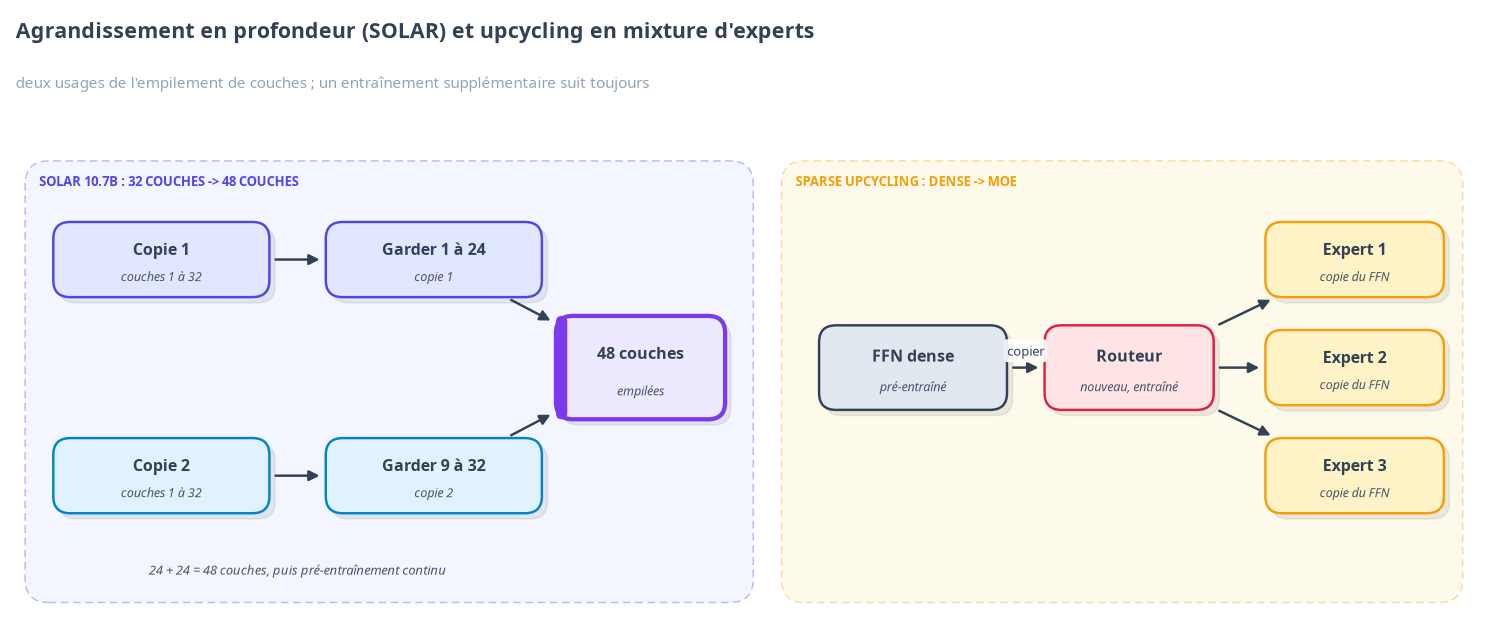

In [12]:
d = Diagram(15.6, 5.6, title="Agrandissement en profondeur (SOLAR) et upcycling en mixture d'experts",
            subtitle="deux usages de l'empilement de couches ; un entraînement supplémentaire suit toujours")
d.group(0.15, 0.25, 7.9, 4.95, "SOLAR 10.7B : 32 couches -> 48 couches", INDIGO)
d.box("c1", 1.6, 3.9, "Copie 1", sub="couches 1 à 32", color=INDIGO, w=2.3, h=0.8)
d.box("c2", 1.6, 1.6, "Copie 2", sub="couches 1 à 32", color=SKY, w=2.3, h=0.8)
d.box("k1", 4.5, 3.9, "Garder 1 à 24", sub="copie 1", color=INDIGO, w=2.3, h=0.8)
d.box("k2", 4.5, 1.6, "Garder 9 à 32", sub="copie 2", color=SKY, w=2.3, h=0.8)
d.box("st", 6.7, 2.75, "48 couches", sub="empilées", color=VIOLET, kind="model", w=1.8, h=1.1)
d.arrow("c1", "k1"); d.arrow("c2", "k2"); d.arrow("k1", "st"); d.arrow("k2", "st")
d.note(3.05, 0.6, "24 + 24 = 48 couches, puis pré-entraînement continu", fontsize=8.5)
d.group(8.2, 0.25, 15.45, 4.95, "sparse upcycling : dense -> MoE", AMBER)
d.box("ffn", 9.6, 2.75, "FFN dense", sub="pré-entraîné", color=SLATE, w=2.0)
d.box("rt", 11.9, 2.75, "Routeur", sub="nouveau, entraîné", color=ROSE, w=1.8)
for i, nm in enumerate(["e1", "e2", "e3"]):
    d.box(nm, 14.3, 3.9 - i * 1.15, f"Expert {i + 1}", sub="copie du FFN", color=AMBER, w=1.9, h=0.8)
    d.arrow("rt", nm)
d.arrow("ffn", "rt", "copier")
d.show()

**Concaténation.** Au lieu de sommer, on juxtapose les paramètres : deux adaptateurs LoRA
de rangs $r_1$ et $r_2$ concaténés donnent un adaptateur de rang $r_1 + r_2$ (figure 7-20).
Algébriquement, $[B_1\; B_2]\begin{bmatrix}A_1\\A_2\end{bmatrix} = B_1A_1 + B_2A_2$ : la
concaténation applique **la somme des deux mises à jour**, mais garde tous les paramètres.
Le livre la déconseille : elle ne réduit pas la mémoire par rapport à servir les deux
adaptateurs séparément.

In [13]:
rng = np.random.default_rng(0)
dd = 896
B1, A1 = rng.normal(size=(dd, 8)), rng.normal(size=(8, dd))
B2, A2 = rng.normal(size=(dd, 16)), rng.normal(size=(16, dd))
Bc, Ac = np.hstack([B1, B2]), np.vstack([A1, A2])
pd.DataFrame({"valeur": [f"{np.abs(Bc @ Ac - (B1 @ A1 + B2 @ A2)).max():.1e}", str(np.linalg.matrix_rank(Bc @ Ac)),
                         f"{Bc.size + Ac.size:,}".replace(",", " "),
                         f"{B1.size + A1.size + B2.size + A2.size:,}".replace(",", " "),
                         f"{8 * 2 * dd:,} à {16 * 2 * dd:,}".replace(",", " ")]},
             index=["écart max entre [B1 B2][A1; A2] et B1A1 + B2A2", "rang de l'adaptateur concaténé",
                    "paramètres de l'adaptateur concaténé", "paramètres des deux adaptateurs séparés",
                    "paramètres d'un adaptateur fusionné par somme (rang 8 à 16)"])

,valeur
écart max entre [B1 B2][A1; A2] et B1A1 + B2A2,1.4e-14
rang de l'adaptateur concaténé,24
paramètres de l'adaptateur concaténé,43 008
paramètres des deux adaptateurs séparés,43 008
paramètres d'un adaptateur fusionné par somme (rang 8 à 16),14 336 à 28 672


> **À retenir.** Trois familles de fusion : **somme** (moyenne, arithmétique des tâches,
> SLERP, TIES, DARE), **empilement** de couches (frankenmerge, SOLAR, upcycling en MoE,
> suivi d'un entraînement) et **concaténation** (simple mais sans gain de mémoire).

## 6. Choisir un modèle de base, une méthode et un framework (section *Finetuning frameworks and base models*)

Le livre résume la mise en œuvre à trois choix.

**Le modèle de base.** En exploration, partir du modèle le plus puissant que l'on peut se
permettre : s'il échoue, les plus faibles échoueront aussi. Pour le finetuning, deux
chemins (repris d'un guide d'OpenAI) :

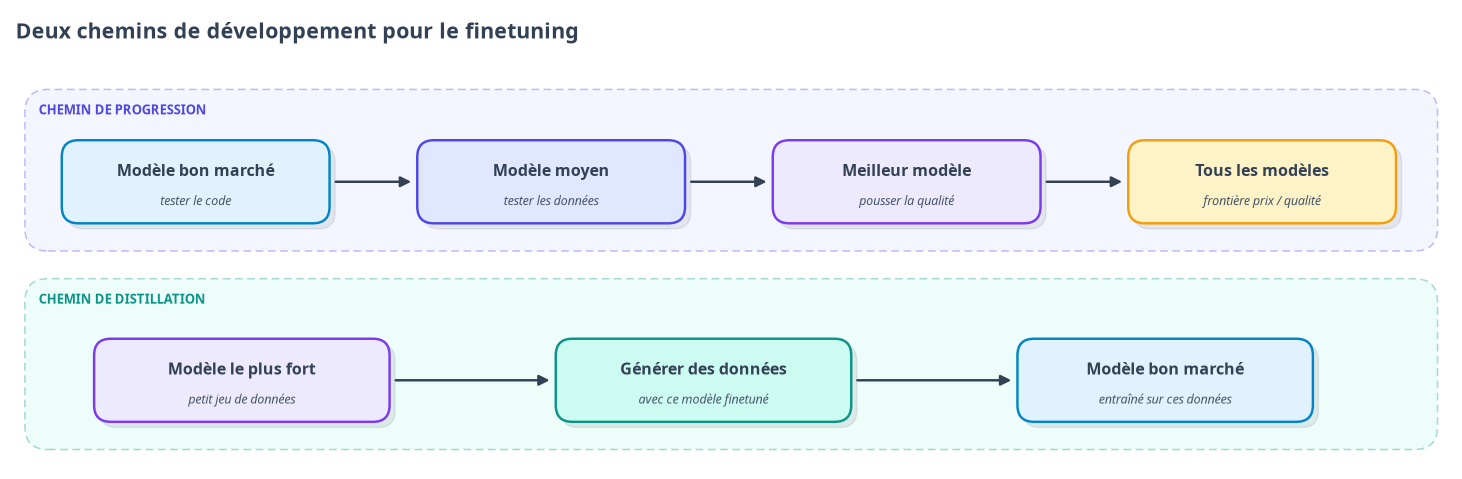

In [14]:
d = Diagram(15.6, 4.4, title="Deux chemins de développement pour le finetuning")
d.group(0.15, 2.35, 15.45, 4.1, "chemin de progression", INDIGO)
d.flow([("p1", "Modèle bon marché", "tester le code"), ("p2", "Modèle moyen", "tester les données"),
        ("p3", "Meilleur modèle", "pousser la qualité"), ("p4", "Tous les modèles", "frontière prix / qualité")],
       y=3.1, x0=2.0, dx=3.85, w=2.9, colors=[SKY, INDIGO, VIOLET, AMBER])
d.group(0.15, 0.2, 15.45, 2.05, "chemin de distillation", TEAL)
d.flow([("d1", "Modèle le plus fort", "petit jeu de données"), ("d2", "Générer des données", "avec ce modèle finetuné"),
        ("d3", "Modèle bon marché", "entraîné sur ces données")],
       y=0.95, x0=2.5, dx=5.0, w=3.2, colors=[VIOLET, TEAL, SKY])
d.show()

La première étape du chemin de progression rappelle l'anecdote de l'auteure : un
entraînement d'une nuit perdu parce que la sauvegarde visait un dossier inexistant.
Testez toujours la chaîne complète sur le plus petit modèle d'abord.

**La méthode.** Commencer par LoRA (peu coûteuse), tenter le finetuning complet ensuite si
besoin. Le volume de données compte : quelques centaines d'exemples suffisent rarement à
un finetuning complet, alors que LoRA s'en contente souvent ; et LoRA facilite le service
de nombreux modèles sur une même base (cours 3).

**Le framework.** Une API de finetuning (on envoie des données, on récupère un modèle) est
le plus simple, mais limite le choix des modèles et des réglages. Les frameworks
(LLaMA-Factory, unsloth, PEFT, Axolotl, LitGPT) offrent toute la souplesse, au prix de
fournir soi-même le calcul ; au-delà d'une machine, il faut de l'entraînement distribué
(DeepSpeed, PyTorch Distributed, ColossalAI).

> **À retenir.** Base : le plus fort possible en exploration, puis progression ou
> distillation. Méthode : LoRA d'abord. Framework : API pour la simplicité, framework
> ouvert pour le contrôle.

## 7. Le taux d'apprentissage (section *Finetuning hyperparameters*)

Le **taux d'apprentissage** est la taille du pas. Trop petit, on n'avance pas ; trop grand,
on dépasse le but et l'entraînement oscille ou diverge. Le livre indique une plage typique
de $10^{-7}$ à $10^{-3}$ (pour le finetuning complet ; LoRA tolère des taux plus élevés car
ses paramètres partent de zéro), et l'usage de prendre le taux de fin de pré-entraînement
multiplié par 0,1 à 1. On le fait aussi varier au cours de l'entraînement
(**planification**, *learning rate schedule*) :

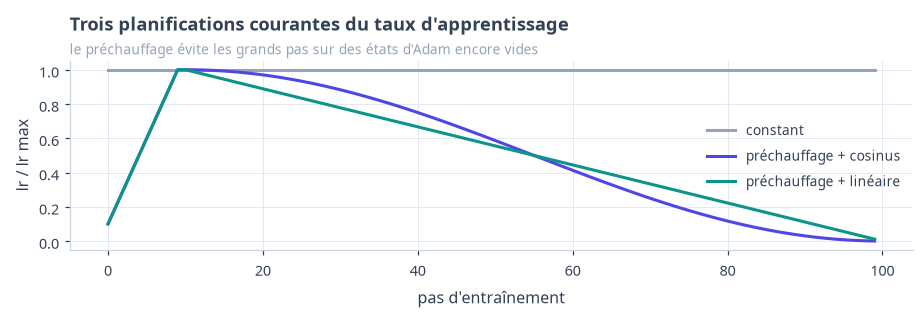

In [15]:
total, warm = 100, 10
steps = np.arange(total)
sched = {
    "constant": np.full(total, 1.0),
    "préchauffage + cosinus": np.where(steps < warm, (steps + 1) / warm, 0.5 * (1 + np.cos(np.pi * (steps - warm) / (total - warm)))),
    "préchauffage + linéaire": np.where(steps < warm, (steps + 1) / warm, 1 - (steps - warm) / (total - warm)),
}
fig, ax = plt.subplots(figsize=(8.5, 3.0))
for (k, v), col in zip(sched.items(), [GRAY, INDIGO, TEAL]):
    ax.plot(steps, v, color=col, label=k)
ax.set_xlabel("pas d'entraînement"); ax.set_ylabel("lr / lr max"); ax.legend(fontsize=9)
c7.title_sub(ax, "Trois planifications courantes du taux d'apprentissage", "le préchauffage évite les grands pas sur des états d'Adam encore vides")
plt.tight_layout(); plt.show()

**Expérience : balayage du taux d'apprentissage.** Même finetuning LoRA que le cours 3
(160 tickets, 2 époques), pour cinq taux maximaux, avec planification cosinus.

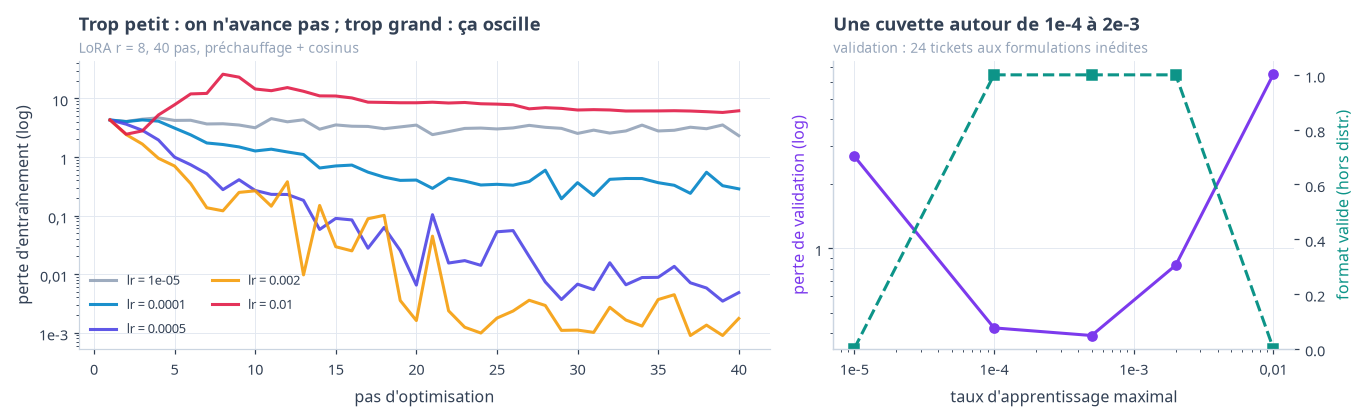

In [16]:
train_t = c7.make_tickets(160, seed=0)
val_t = c7.make_tickets(24, seed=2, split="test")
lr_runs = {}
for lr in [1e-5, 1e-4, 5e-4, 2e-3, 1e-2]:
    lr_runs[lr] = c7.gpu_retry(c7.lora_ticket_run, train_t, val=val_t, eval_sets={"hors distribution": val_t}, lr=lr,
                               eval_every=5)
c7.log_vram("nb4 lr")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
cols = [GRAY, SKY, INDIGO, AMBER, ROSE]
for (lr, r_), col in zip(lr_runs.items(), cols):
    h = r_["history"]
    axes[0].plot(h.step, h.loss, color=col, alpha=0.9, label=f"lr = {lr:g}")
axes[0].set_yscale("log"); c7.sci_log(axes[0], "y"); axes[0].set_xlabel("pas d'optimisation"); axes[0].set_ylabel("perte d'entraînement (log)")
axes[0].legend(fontsize=8.5, ncol=2)
c7.title_sub(axes[0], "Trop petit : on n'avance pas ; trop grand : ça oscille", "LoRA r = 8, 40 pas, préchauffage + cosinus")
lrs = list(lr_runs)
axes[1].plot(lrs, [lr_runs[l]["history"].val_loss[-1] for l in lrs], "o-", color=VIOLET, label="perte de validation finale")
ax2 = axes[1].twinx()
ax2.plot(lrs, [lr_runs[l]["scores"]["hors distribution"]["format valide"] for l in lrs], "s--", color=TEAL, label="format valide")
ax2.set_ylim(0, 1.05); ax2.set_ylabel("format valide (hors distr.)", color=TEAL); ax2.grid(False)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); c7.sci_log(axes[1], "both"); axes[1].set_xlabel("taux d'apprentissage maximal")
axes[1].set_ylabel("perte de validation (log)", color=VIOLET)
c7.title_sub(axes[1], "Une cuvette autour de 1e-4 à 2e-3", "validation : 24 tickets aux formulations inédites")
plt.tight_layout(); plt.show()

Les courbes illustrent les diagnostics du livre : avec $10^{-5}$, la perte descend à peine
en 40 pas (il faudrait beaucoup plus d'étapes) ; aux taux intermédiaires, elle descend vite
et proprement ; au taux le plus élevé, la courbe devient bruitée, remonte par endroits, et
le modèle peut se dégrader. Règle pratique : **augmenter le taux tant que la courbe reste
stable**.

> **À retenir.** Le taux d'apprentissage est le premier hyperparamètre à régler : une
> courbe qui stagne signale un taux trop petit, une courbe qui oscille un taux trop grand.
> Planification usuelle : préchauffage puis décroissance.

## 8. Taille de lot, accumulation de gradient et nombre d'époques (section *Finetuning hyperparameters*)

**Taille de lot.** Le gradient d'un lot de $B$ exemples est une moyenne de $B$ gradients
individuels : sa variance autour du « vrai » gradient décroît comme $\sigma^2 / B$. Un lot
trop petit (le livre cite moins de 8) donne des mises à jour bruitées ; un grand lot est
plus stable mais coûte de la mémoire (activations). Mesurons ce bruit sur le réseau
`digits`.

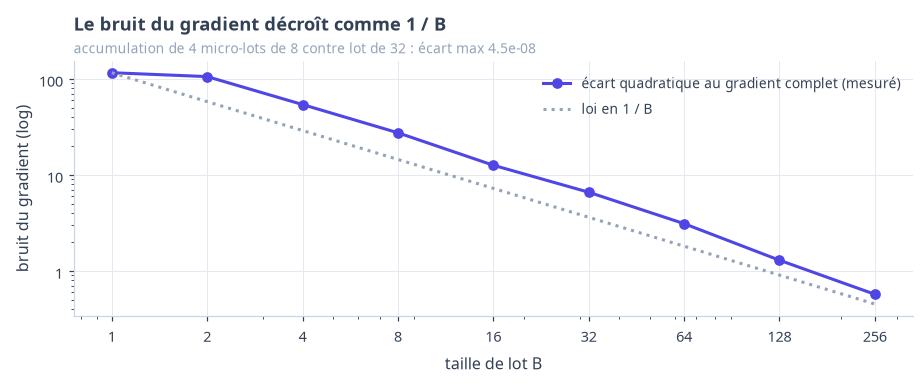

In [17]:
net = c7.make_mlp(0, S.hidden); c7.set_flat(net, S.base)
Xd = torch.tensor(T["occulté"][0], dtype=torch.float32); yd = torch.tensor(T["occulté"][1])


def grad_of(idx):
    net.zero_grad()
    torch.nn.functional.cross_entropy(net(Xd[idx]), yd[idx]).backward()
    return torch.cat([p.grad.flatten() for p in net.parameters()]).clone()


g_full = grad_of(torch.arange(len(Xd)))
gen = torch.Generator().manual_seed(0)
Bs = [1, 2, 4, 8, 16, 32, 64, 128, 256]
var = [np.mean([((grad_of(torch.randperm(len(Xd), generator=gen)[:B]) - g_full) ** 2).sum().item() for _ in range(40)]) for B in Bs]
# accumulation : 4 micro-lots de 8 = 1 lot de 32
idx32 = torch.randperm(len(Xd), generator=gen)[:32]
g32 = grad_of(idx32)
g_acc = sum(grad_of(idx32[i * 8:(i + 1) * 8]) for i in range(4)) / 4

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.loglog(Bs, var, "o-", color=INDIGO, label="écart quadratique au gradient complet (mesuré)")
ax.loglog(Bs, var[0] / np.array(Bs), ":", color=GRAY, label="loi en 1 / B")
c7.sci_log(ax, "y"); ax.set_xticks(Bs, [str(b) for b in Bs]); ax.set_xlabel("taille de lot B"); ax.set_ylabel("bruit du gradient (log)")
ax.legend(fontsize=9)
c7.title_sub(ax, "Le bruit du gradient décroît comme 1 / B",
             f"accumulation de 4 micro-lots de 8 contre lot de 32 : écart max {(g_acc - g32).abs().max().item():.1e}")
plt.tight_layout(); plt.show()

La loi en $1/B$ se vérifie (avec une légère courbure due au tirage sans remise dans un jeu
fini). Quand la mémoire interdit les grands lots, l'**accumulation de gradient** calcule
plusieurs micro-lots, additionne leurs gradients et ne met à jour les poids qu'ensuite :
comme la perte d'un lot est une moyenne, la moyenne des gradients de 4 micro-lots de 8 est
**exactement** le gradient du lot de 32 (écart au niveau des arrondis, affiché sous le
titre). On paie en temps ce qu'on économise en mémoire ; c'est ce que fait `c7.train_sft`
avec `grad_accum=2`.

**Nombre d'époques.** Une époque est un passage sur tout le jeu d'entraînement. Le livre :
1 à 2 époques pour des millions d'exemples, 4 à 10 pour quelques milliers. Le diagnostic
se fait sur l'écart entre pertes d'entraînement et de validation : si les deux baissent,
continuer ; si la perte d'entraînement baisse et que celle de validation **remonte**, le
modèle **sur-apprend**. Provoquons-le : 24 tickets seulement (6 par catégorie), 15 époques,
taux constant.

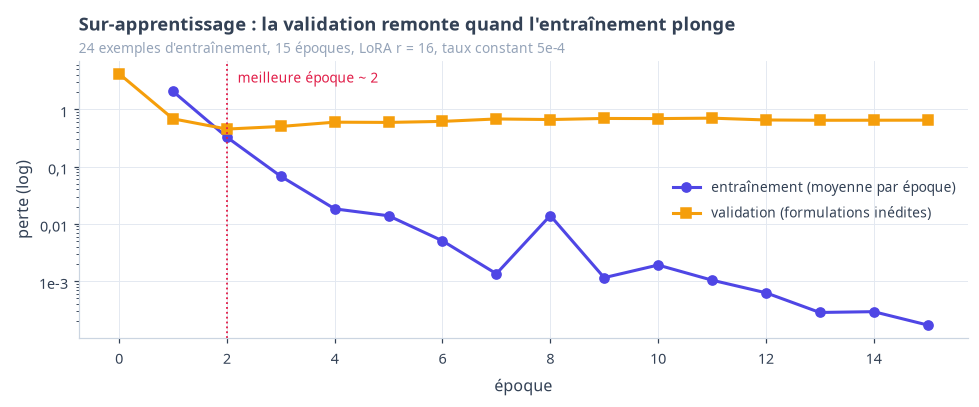

In [18]:
small_train = c7.make_tickets(24, seed=5)
ov = c7.gpu_retry(c7.lora_ticket_run, small_train, val=val_t, lr=5e-4, epochs=15, batch_size=2, grad_accum=2,
                  eval_every=6, schedule="constant", r=16)
h = ov["history"]
c7.log_vram("nb4 epochs")
ep_train = [np.mean(h.loss[i * 6:(i + 1) * 6]) for i in range(len(h.loss) // 6)]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(1, len(ep_train) + 1), ep_train, "o-", color=INDIGO, label="entraînement (moyenne par époque)")
ax.plot(np.array(h.val_step) / 6, h.val_loss, "s-", color=AMBER, label="validation (formulations inédites)")
best_ep = np.array(h.val_step)[int(np.argmin(h.val_loss))] / 6
ax.axvline(best_ep, color=ROSE, ls=":", lw=1.2); ax.text(best_ep + 0.2, max(h.val_loss) * 0.7, f"meilleure époque ~ {best_ep:.0f}", color=ROSE, fontsize=9)
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("époque"); ax.set_ylabel("perte (log)"); ax.legend(fontsize=9)
c7.title_sub(ax, "Sur-apprentissage : la validation remonte quand l'entraînement plonge",
             "24 exemples d'entraînement, 15 époques, LoRA r = 16, taux constant 5e-4")
plt.tight_layout(); plt.show()

La perte d'entraînement tend vers zéro : le modèle récite ses 24 exemples. La perte de
validation atteint son minimum après quelques époques puis remonte : au-delà, chaque
époque supplémentaire dégrade la généralisation. On arrêterait l'entraînement au minimum
de validation (*early stopping*), ou l'on ajouterait des données.

> **À retenir.** Lot : assez grand pour un gradient stable, limité par la mémoire ;
> l'accumulation de gradient l'émule exactement. Époques : surveiller l'écart entre
> entraînement et validation, et s'arrêter quand la validation remonte.

## 9. Le poids de la perte du prompt (section *Finetuning hyperparameters*)

En finetuning d'instructions, chaque exemple contient un prompt et une réponse. À
l'inférence, le prompt est fourni par l'utilisateur : seule la réponse doit être générée.
Le **poids de la perte du prompt** (*prompt loss weight*) $w_p$ règle la contribution des
tokens du prompt :
$$\mathcal L = \frac{w_p \sum_{t \in \text{prompt}} \ell_t + \sum_{t \in \text{réponse}} \ell_t}{w_p\, n_{\text{prompt}} + n_{\text{réponse}}}.$$
À 100 %, prompt et réponse comptent autant ; à 0 %, on n'apprend que la réponse ; le livre
indique 10 % comme valeur par défaut courante. Dans notre tâche, le prompt fait environ
75 tokens et la réponse une vingtaine : avec $w_p = 1$, près de 80 % du signal porte sur la
recopie du message système et du message client. Comparons trois valeurs (perte de
validation calculée **sur la réponse seule** dans tous les cas, pour comparer ce qui
compte).

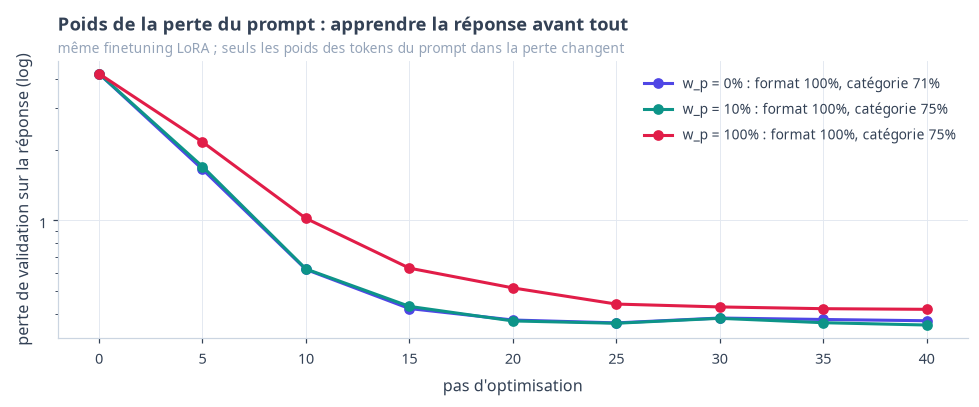

,format valide,catégorie exacte,urgence exacte
w_p = 0%,1.0,0.708,0.958
w_p = 10%,1.0,0.750,0.958
w_p = 100%,1.0,0.750,0.625


In [19]:
plw_runs = {}
for w_p in [0.0, 0.1, 1.0]:
    plw_runs[w_p] = c7.gpu_retry(c7.lora_ticket_run, train_t, val=val_t, eval_sets={"hors distribution": val_t},
                                 prompt_loss_weight=w_p, eval_every=5)
fig, ax = plt.subplots(figsize=(9, 3.8))
for (w_p, r_), col in zip(plw_runs.items(), [INDIGO, TEAL, ROSE]):
    h = r_["history"]; sc = r_["scores"]["hors distribution"]
    ax.plot(h.val_step, h.val_loss, "o-", color=col,
            label=f"w_p = {w_p:.0%} : format {sc['format valide']:.0%}, catégorie {sc['catégorie exacte']:.0%}")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'optimisation"); ax.set_ylabel("perte de validation sur la réponse (log)")
ax.legend(fontsize=9)
c7.title_sub(ax, "Poids de la perte du prompt : apprendre la réponse avant tout",
             "même finetuning LoRA ; seuls les poids des tokens du prompt dans la perte changent")
plt.tight_layout(); plt.show()
pd.DataFrame({f"w_p = {k:.0%}": v["scores"]["hors distribution"] for k, v in plw_runs.items()}).T.round(3)

Avec $w_p = 1$, une grande partie de la capacité et du gradient est dépensée à modéliser
les prompts (message système répété, formules de politesse), et la perte sur la réponse
descend plus lentement à nombre de pas égal, et les scores peuvent en pâtir (comparez la
ligne 100 % du tableau aux deux autres) ; les valeurs 0 et 10 % se valent à peu près sur
cette tâche. Le petit poids sur le prompt peut aider quand les prompts sont eux-mêmes
informatifs (vocabulaire du domaine) ; il nuit quand ils sont répétitifs. Comme toujours,
c'est l'évaluation qui tranche.

> **À retenir.** Le poids de la perte du prompt concentre l'apprentissage sur ce que le
> modèle devra produire. 0 à 10 % est le réglage courant ; 100 % dilue le signal dans la
> recopie des prompts.

## Synthèse

- La **fusion** combine des paramètres (un seul modèle à servir), là où l'ensemble combine
  des sorties. Elle permet le multi-tâche sans oubli catastrophique, le déploiement sur
  appareil et l'apprentissage fédéré.
- Fusion par **somme** : moyenne, arithmétique des tâches (addition et négation de
  capacités), SLERP (conserve la norme) ; **élagage** des vecteurs de tâche (TIES, DARE),
  très redondants ; **empilement** de couches (SOLAR, upcycling en MoE) et
  **concaténation** (sans gain mémoire).
- **Tactiques** : modèle de base le plus fort en exploration, LoRA d'abord ; taux
  d'apprentissage réglé sur la forme des courbes ; lot aussi grand que la mémoire le
  permet (accumulation sinon) ; époques arrêtées quand la validation remonte ; poids de la
  perte du prompt faible.

Le livre conclut que le finetuning lui-même est la partie facile : obtenir de **bonnes
données** est la partie difficile. C'est l'objet du chapitre 8.

In [20]:
llm.free_gpu()